# Hipótese 6: Alarme em portas + usadas(extremos ou meio)

## 1. Contexto e Fundamentação Teórica
As Portas de Plataforma (PSDs) são equipamentos de segurança distribuídos ao longo das plataformas e submetidos continuamente à interação com os passageiros durante o embarque e o desembarque. Embora todas realizem ciclos de abertura e fechamento, sua localização pode gerar diferentes níveis de exposição ao fluxo de pessoas. Portas próximas a escadas, escadas rolantes, elevadores e acessos à plataforma tendem a receber maior concentração de passageiros do que aquelas situadas em regiões mais afastadas.

A maior interação com passageiros pode aumentar tanto a ocorrência de obstáculos durante o movimento da pessoas quanto o desgaste dos componentes mecânicos e eletrônicos das portas. Consequentemente, portas mais utilizadas podem apresentar maior frequência de diferentes alarmes e defeitos, como obstáculos (`OBS`), esforço excessivo, tempos excedidos de abertura ou fechamento e falhas relacionadas aos sensores.

A hipótese operacional deste estudo estabelece, portanto, que a posição da porta na plataforma está associada à frequência de alarmes e defeitos, com expectativa de maior incidência nas portas mais utilizadas, geralmente próximas ao centro ou aos acessos em comparação às portas menos utilizadas, localizadas nas extremidades. A análise contemplará os diferentes tipos de alarme vinculados a cada porta. Especificamente para os registros `OBS`, que representam obstáculos, serão consideradas apenas ocorrências com duração superior a 60 segundos; registros `OBS` com duração igual ou inferior a 60 segundos, ausente ou inválida serão desconsiderados. Esse filtro não será aplicado aos demais tipos de alarme.

Como a base não contém medições diretas do fluxo de passageiros nem a localização dos acessos de cada estação, a posição geométrica da porta será utilizada como aproximação de uso. Dessa forma, os resultados permitirão identificar associações entre posição e frequência de alarmes, mas não comprovar, isoladamente, que o fluxo de passageiros é a causa direta dos defeitos encontrados.

---

## 2. Importação das bibliotecas e auditoria inicial

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

alarmes_path = "../../data/Alarmes do sistema de PSD.xlsx"
df_alarmes = pd.read_excel(alarmes_path)

print(f"Dimensão da base: {df_alarmes.shape[0]:,} linhas × {df_alarmes.shape[1]} colunas")
display(df_alarmes.head())

Dimensão da base: 150,003 linhas × 7 colunas


,TAG,Horário do Alarme,Estação,Porta,Alarme,Horário da Normalizacao,Tempo de Normalização
0,PSD_FAL_FAL2_PDM09_OBS,2026-05-12 08:16:52.657,FAL,9.0,OBS,2026-05-12 08:16:53.670,"0 dias, 00:00:01"
1,PSD_LUZ_LUZ1_PDM08_OBS,2026-05-12 08:15:09.913,LUZ,8.0,OBS,2026-05-12 08:15:10.917,"0 dias, 00:00:01"
2,PSD_FAL_FAL1_PDM15_OBS,2026-05-12 08:14:06.657,FAL,15.0,OBS,2026-05-12 08:14:07.670,"0 dias, 00:00:01"
3,PSD_LUZ_LUZ1_PDM19_OBS,2026-05-12 08:09:31.930,LUZ,19.0,OBS,2026-05-12 08:09:32.917,"0 dias, 00:00:01"
4,PSD_FRE_FRE1_PDM14_OBS,2026-05-12 08:05:05.830,FRE,14.0,OBS,2026-05-12 08:05:14.847,"0 dias, 00:00:09"


In [46]:
# Auditoria inicial da base, sem alterar ou excluir registros
resumo_colunas = pd.DataFrame({
    "tipo": df_alarmes.dtypes.astype(str),
    "valores_ausentes": df_alarmes.isna().sum(),
    "percentual_ausente": (df_alarmes.isna().mean() * 100).round(2),
    "valores_unicos": df_alarmes.nunique(dropna=True),
})

print(f"Duplicatas exatas: {df_alarmes.duplicated().sum():,}")
display(resumo_colunas)

Duplicatas exatas: 0


,tipo,valores_ausentes,percentual_ausente,valores_unicos
TAG,str,1,0.00,379
Horário do Alarme,datetime64[us],37252,24.83,36477
Estação,str,3,0.00,6
Porta,float64,3,0.00,24
Alarme,str,3,0.00,8
Horário da Normalizacao,datetime64[us],3,0.00,35360
Tempo de Normalização,str,3,0.00,56673


## 3. Pré-processamento e Limpeza dos Dados

A base não possui duplicatas exatas, mas contém registros sem horário de alarme e três linhas sem identificação de estação, porta e tipo de alarme. Nesta etapa, os dados serão tratados sem modificar a base original. As regras de duração serão aplicadas apenas aos alarmes de obstáculo (`OBS`); os demais tipos de alarme serão preservados para a análise.

In [47]:
# Cópia de trabalho para preservar a base original
df = df_alarmes.copy()

colunas_identificacao = ["Estação", "Porta", "Alarme"]
linhas_sem_identificacao = df[colunas_identificacao].isna().any(axis=1)

print(f"Linhas sem identificação removidas: {linhas_sem_identificacao.sum():,}")
display(df.loc[linhas_sem_identificacao])

df = df.loc[~linhas_sem_identificacao].copy().reset_index(drop=True)

print(f"Dimensão após a remoção: {df.shape[0]:,} linhas × {df.shape[1]} colunas")

Linhas sem identificação removidas: 3


,TAG,Horário do Alarme,Estação,Porta,Alarme,Horário da Normalizacao,Tempo de Normalização
150000,NaN,NaT,NaN,NaN,NaN,NaT,NaN
150001,Nenhum filtro aplicado,NaT,NaN,NaN,NaN,NaT,NaN
150002,Exported data exceeded the allowed volume. Som...,NaT,NaN,NaN,NaN,NaT,NaN


Dimensão após a remoção: 150,000 linhas × 7 colunas


In [48]:
# Padronização dos tipos e cálculo da duração dos alarmes
df["TAG"] = df["TAG"].astype("string").str.strip().str.upper()
df["Estação"] = df["Estação"].astype("string").str.strip().str.upper()
df["Alarme"] = df["Alarme"].astype("string").str.strip().str.upper()
df["Porta"] = pd.to_numeric(df["Porta"], errors="coerce").astype("Int64")
df["Horário do Alarme"] = pd.to_datetime(df["Horário do Alarme"], errors="coerce")
df["Horário da Normalizacao"] = pd.to_datetime(
    df["Horário da Normalizacao"], errors="coerce"
)

df["Duração em segundos"] = (
    df["Horário da Normalizacao"] - df["Horário do Alarme"]
).dt.total_seconds()

print(f"Durações ausentes: {df['Duração em segundos'].isna().sum():,}")
display(df.dtypes.rename("tipo").to_frame())
display(df.head())

Durações ausentes: 37,249


,tipo
TAG,string
Horário do Alarme,datetime64[us]
Estação,string
Porta,Int64
Alarme,string
Horário da Normalizacao,datetime64[us]
Tempo de Normalização,str
Duração em segundos,float64


,TAG,Horário do Alarme,Estação,Porta,Alarme,Horário da Normalizacao,Tempo de Normalização,Duração em segundos
0,PSD_FAL_FAL2_PDM09_OBS,2026-05-12 08:16:52.657,FAL,9,OBS,2026-05-12 08:16:53.670,"0 dias, 00:00:01",1.013
1,PSD_LUZ_LUZ1_PDM08_OBS,2026-05-12 08:15:09.913,LUZ,8,OBS,2026-05-12 08:15:10.917,"0 dias, 00:00:01",1.004
2,PSD_FAL_FAL1_PDM15_OBS,2026-05-12 08:14:06.657,FAL,15,OBS,2026-05-12 08:14:07.670,"0 dias, 00:00:01",1.013
3,PSD_LUZ_LUZ1_PDM19_OBS,2026-05-12 08:09:31.930,LUZ,19,OBS,2026-05-12 08:09:32.917,"0 dias, 00:00:01",0.987
4,PSD_FRE_FRE1_PDM14_OBS,2026-05-12 08:05:05.830,FRE,14,OBS,2026-05-12 08:05:14.847,"0 dias, 00:00:09",9.017


In [49]:
# Filtro específico para alarmes de obstáculo (OBS)
eh_obs = df["Alarme"].eq("OBS")
obs_acima_60s = eh_obs & df["Duração em segundos"].gt(60)
outros_alarmes = ~eh_obs

df_filtrado = df.loc[obs_acima_60s | outros_alarmes].copy().reset_index(drop=True)

resumo_filtro_obs = pd.DataFrame({
    "Registros": [
        obs_acima_60s.sum(),
        (eh_obs & df["Duração em segundos"].le(60)).sum(),
        (eh_obs & df["Duração em segundos"].isna()).sum(),
        outros_alarmes.sum(),
        len(df_filtrado),
    ]
}, index=[
    "OBS mantidos (> 60 s)",
    "OBS removidos (≤ 60 s)",
    "OBS removidos (sem duração)",
    "Demais alarmes mantidos",
    "Total após o filtro",
])

display(resumo_filtro_obs)

,Registros
OBS mantidos (> 60 s),54424
OBS removidos (≤ 60 s),28058
OBS removidos (sem duração),28638
Demais alarmes mantidos,38880
Total após o filtro,93304


In [50]:
# Extração dos identificadores presentes na TAG
partes_tag = df_filtrado["TAG"].str.extract(
    r"_(?P<Estacao_TAG>[A-Z]{3})(?P<Via>[12])_"
    r"(?P<Componente>PDM|MDU)(?P<Porta_TAG>\d{1,2})_"
)

df_filtrado["Estacao_TAG"] = partes_tag["Estacao_TAG"]
df_filtrado["Via"] = partes_tag["Via"].astype("Int64")
df_filtrado["Componente"] = partes_tag["Componente"]
df_filtrado["Porta_TAG"] = pd.to_numeric(
    partes_tag["Porta_TAG"], errors="coerce"
).astype("Int64")

portas_divergentes = (
    df_filtrado["Porta_TAG"].notna()
    & df_filtrado["Porta"].ne(df_filtrado["Porta_TAG"])
).sum()

print(f"TAGs não interpretadas: {df_filtrado['Componente'].isna().sum():,}")
print(f"Divergências entre Porta e Porta_TAG: {portas_divergentes:,}")
display(pd.crosstab(df_filtrado["Componente"], df_filtrado["Alarme"], margins=True))

TAGs não interpretadas: 0
Divergências entre Porta e Porta_TAG: 0


Alarme,CA,CSD,FC,FO,LSD,OA,OBS,STS,All
Componente,,,,,,,,,
MDU,0,0,0,0,0,0,0,12822,12822
PDM,4168,4102,4437,4617,4606,4128,54424,0,80482
All,4168,4102,4437,4617,4606,4128,54424,12822,93304


In [51]:
# Seleção dos alarmes vinculados diretamente às portas (PDM)
df_portas = (
    df_filtrado.loc[df_filtrado["Componente"].eq("PDM")]
    .copy()
    .reset_index(drop=True)
)

print(f"Registros MDU/STS removidos: {len(df_filtrado) - len(df_portas):,}")
print(f"Registros PDM mantidos: {len(df_portas):,}")
display(df_portas["Alarme"].value_counts().rename("Registros").to_frame())

Registros MDU/STS removidos: 12,822
Registros PDM mantidos: 80,482


,Registros
Alarme,
OBS,54424
FO,4617
LSD,4606
FC,4437
CA,4168
OA,4128
CSD,4102


In [52]:
# Identificação de cada combinação estação-via e de cada porta física
df_portas["Plataforma_ID"] = (
    df_portas["Estação"]
    + "_V"
    + df_portas["Via"].astype("string")
)
df_portas["Porta_ID"] = (
    df_portas["Plataforma_ID"]
    + "_PDM"
    + df_portas["Porta"].astype("string").str.zfill(2)
)

print(f"Combinações estação-via identificadas: {df_portas['Plataforma_ID'].nunique()}")
print(f"Portas físicas identificadas: {df_portas['Porta_ID'].nunique()}")
display(df_portas[["Estação", "Via", "Porta", "Plataforma_ID", "Porta_ID"]].head())

Combinações estação-via identificadas: 12
Portas físicas identificadas: 257


,Estação,Via,Porta,Plataforma_ID,Porta_ID
0,BUT,1,7,BUT_V1,BUT_V1_PDM07
1,BUT,1,4,BUT_V1,BUT_V1_PDM04
2,FRE,1,4,FRE_V1,FRE_V1_PDM04
3,FRE,1,6,FRE_V1,FRE_V1_PDM06
4,BUT,1,9,BUT_V1,BUT_V1_PDM09


## 4. Análise Exploratória dos Alarmes por Porta

Nesta etapa, será analisada a quantidade de ocorrências válidas registrada por porta física. A comparação será feita por estação e via, preservando o tipo de alarme para permitir tanto a análise geral dos defeitos quanto análises específicas, como a de obstáculos (`OBS`).


In [53]:
# Ranking das portas pela quantidade de ocorrências válidas
ranking_portas = (
    df_portas.groupby(
        ["Porta_ID", "Estação", "Via", "Porta"],
        as_index=False,
        observed=True,
    )
    .agg(
        Total_Alarmes=("Alarme", "size"),
        Tipos_Alarme=("Alarme", "nunique"),
        Primeiro_Alarme=("Horário do Alarme", "min"),
        Ultimo_Alarme=("Horário do Alarme", "max"),
    )
    .sort_values(
        ["Total_Alarmes", "Porta_ID"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

print(f"Portas presentes no ranking: {len(ranking_portas):,}")
display(ranking_portas.head(20))

Portas presentes no ranking: 257


,Porta_ID,Estação,Via,Porta,Total_Alarmes,Tipos_Alarme,Primeiro_Alarme,Ultimo_Alarme
0,BUT_V1_PDM07,BUT,1,7,2935,7,2023-12-02 14:37:36.417,2026-05-11 18:55:45.703
1,BUT_V1_PDM10,BUT,1,10,2777,7,2023-11-10 15:42:04.927,2026-04-01 09:15:30.030
2,BUT_V1_PDM05,BUT,1,5,2508,7,2023-12-15 07:09:45.817,2026-02-27 17:15:41.637
3,BUT_V1_PDM09,BUT,1,9,2502,7,2023-10-24 12:10:09.353,2026-05-05 17:35:17.143
4,BUT_V1_PDM08,BUT,1,8,2466,7,2023-11-10 18:42:34.927,2026-04-26 14:16:22.650
5,BUT_V1_PDM06,BUT,1,6,2463,7,2023-11-30 08:59:01.727,2026-02-10 20:42:41.893
6,BUT_V1_PDM02,BUT,1,2,2449,7,2023-10-28 11:51:43.630,2026-04-07 12:27:18.627
7,BUT_V1_PDM04,BUT,1,4,2436,7,2023-12-21 16:00:44.370,2026-05-10 05:02:52.937
8,BUT_V1_PDM01,BUT,1,1,2429,7,2024-01-21 23:12:46.257,2026-04-04 14:47:54.940
9,BUT_V1_PDM11,BUT,1,11,2337,7,2024-03-11 09:45:41.557,2026-03-28 08:37:04.317


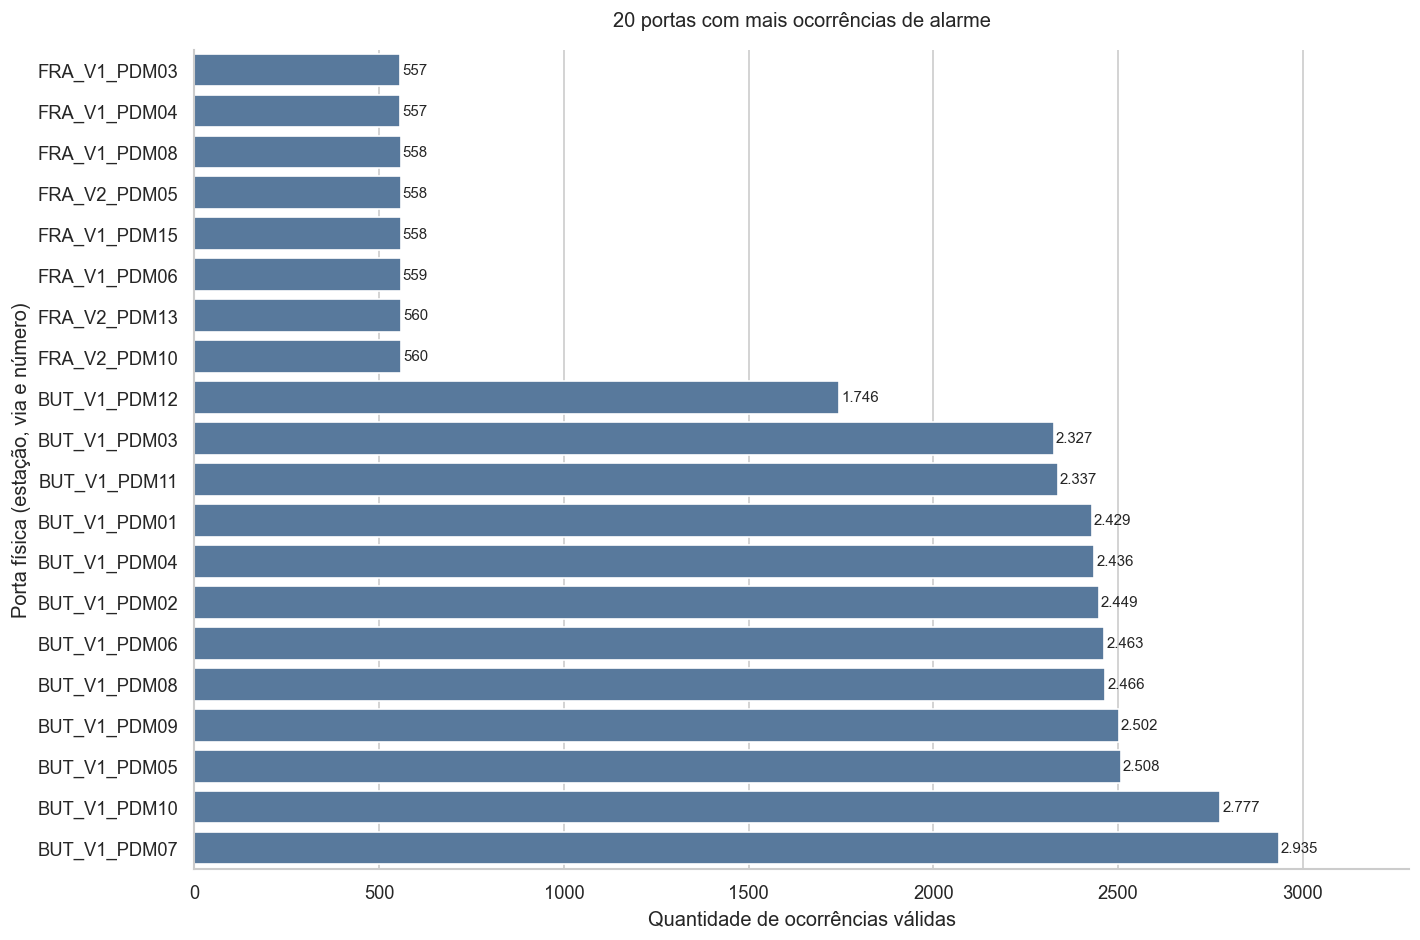

In [54]:
# Visualização das 20 portas com mais ocorrências válidas
top_20_portas = ranking_portas.head(20).sort_values("Total_Alarmes")

fig, ax = plt.subplots(figsize=(12, 8))
sns.barplot(
    data=top_20_portas,
    x="Total_Alarmes",
    y="Porta_ID",
    color="#4C78A8",
    ax=ax,
)

for barra in ax.patches:
    valor = int(barra.get_width())
    ax.text(
        barra.get_width() + 5,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:,}".replace(",", "."),
        va="center",
        fontsize=9,
    )

ax.set_title("20 portas com mais ocorrências de alarme", pad=14)
ax.set_xlabel("Quantidade de ocorrências válidas")
ax.set_ylabel("Porta física (estação, via e número)")
ax.set_xlim(0, top_20_portas["Total_Alarmes"].max() * 1.12)
sns.despine()
plt.tight_layout()
plt.show()

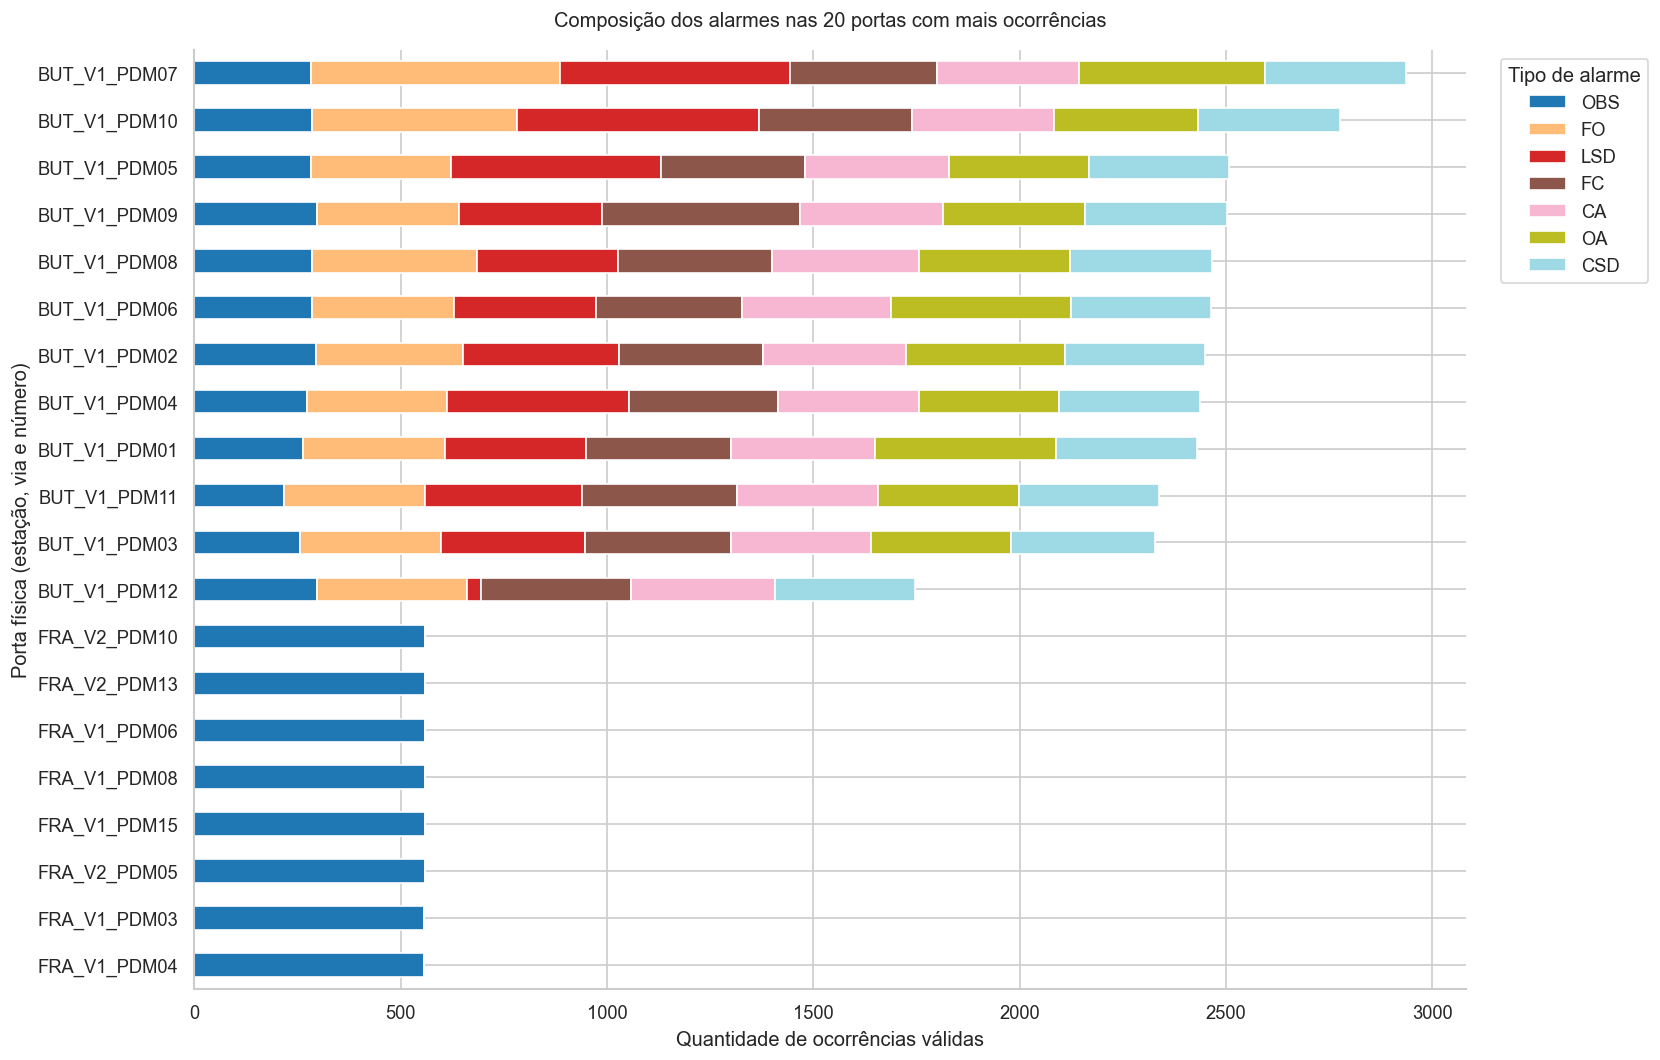

In [55]:
# Composição dos tipos de alarme nas 20 portas do ranking
ordem_top_20 = ranking_portas.head(20)["Porta_ID"].tolist()

alarmes_por_tipo = (
    df_portas.loc[df_portas["Porta_ID"].isin(ordem_top_20)]
    .groupby(["Porta_ID", "Alarme"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(ordem_top_20[::-1])
)

tipos_ordenados = alarmes_por_tipo.sum().sort_values(ascending=False).index
alarmes_por_tipo = alarmes_por_tipo[tipos_ordenados]

ax = alarmes_por_tipo.plot(
    kind="barh",
    stacked=True,
    figsize=(14, 9),
    colormap="tab20",
)
ax.set_title("Composição dos alarmes nas 20 portas com mais ocorrências", pad=14)
ax.set_xlabel("Quantidade de ocorrências válidas")
ax.set_ylabel("Porta física (estação, via e número)")
ax.legend(title="Tipo de alarme", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

## 5. Classificação das Portas por Posição na Plataforma

Para testar a hipótese, as 24 posições de porta de cada via serão divididas em dois grupos de mesmo tamanho:

- **Centro:** portas `07` a `18`;
- **Extremidades:** portas `01` a `06` e `19` a `24`.

Essa divisão é uma aproximação operacional, pois a base não informa a posição das escadas, elevadores e demais acessos de cada plataforma. O uso de 12 posições em cada grupo permite uma comparação equilibrada entre centro e extremidades.

In [56]:
# Classificação de cada registro conforme a posição da porta na plataforma
condicoes_posicao = [
    df_portas["Porta"].between(7, 18),
    (
        df_portas["Porta"].between(1, 6)
        | df_portas["Porta"].between(19, 24)
    ),
]

df_portas["Posicao_Plataforma"] = pd.Series(
    np.select(
        condicoes_posicao,
        ["Centro", "Extremidades"],
        default=None,
    ),
    index=df_portas.index,
    dtype="string",
)

resumo_posicao = (
    df_portas.groupby("Posicao_Plataforma", observed=True)
    .agg(
        Ocorrencias=("Alarme", "size"),
        Portas_Observadas=("Porta_ID", "nunique"),
        Estacoes=("Estação", "nunique"),
        Lados_Vias=("Plataforma_ID", "nunique"),
    )
    .reindex(["Centro", "Extremidades"])
)

print(
    f"Registros sem posição válida: "
    f"{df_portas['Posicao_Plataforma'].isna().sum():,}"
)
display(resumo_posicao)

Registros sem posição válida: 0


,Ocorrencias,Portas_Observadas,Estacoes,Lados_Vias
Posicao_Plataforma,,,,
Centro,41058,130,6,12
Extremidades,39424,127,6,12


In [57]:
# Quantidade de ocorrências por porta física
ocorrencias_por_porta = (
    df_portas.groupby(
        ["Porta_ID", "Estação", "Via", "Porta", "Posicao_Plataforma"],
        as_index=False,
        observed=True,
    )
    .size()
    .rename(columns={"size": "Ocorrencias"})
)

resumo_comparacao = (
    ocorrencias_por_porta.groupby("Posicao_Plataforma", observed=True)
    .agg(
        Portas_Observadas=("Porta_ID", "nunique"),
        Total_Ocorrencias=("Ocorrencias", "sum"),
        Media_por_Porta=("Ocorrencias", "mean"),
        Mediana_por_Porta=("Ocorrencias", "median"),
        Desvio_Padrao=("Ocorrencias", "std"),
        Minimo=("Ocorrencias", "min"),
        Maximo=("Ocorrencias", "max"),
    )
    .reindex(["Centro", "Extremidades"])
    .round(2)
)

media_centro = resumo_comparacao.loc["Centro", "Media_por_Porta"]
media_extremos = resumo_comparacao.loc["Extremidades", "Media_por_Porta"]
diferenca_percentual = (media_centro / media_extremos - 1) * 100

display(resumo_comparacao)
print(
    f"Diferença da média do centro em relação às extremidades: "
    f"{diferenca_percentual:.2f}%"
)

,Portas_Observadas,Total_Ocorrencias,Media_por_Porta,Mediana_por_Porta,Desvio_Padrao,Minimo,Maximo
Posicao_Plataforma,,,,,,,
Centro,130,41058,315.83,161.0,512.78,1,2935
Extremidades,127,39424,310.43,154.0,509.49,1,2508


Diferença da média do centro em relação às extremidades: 1.74%


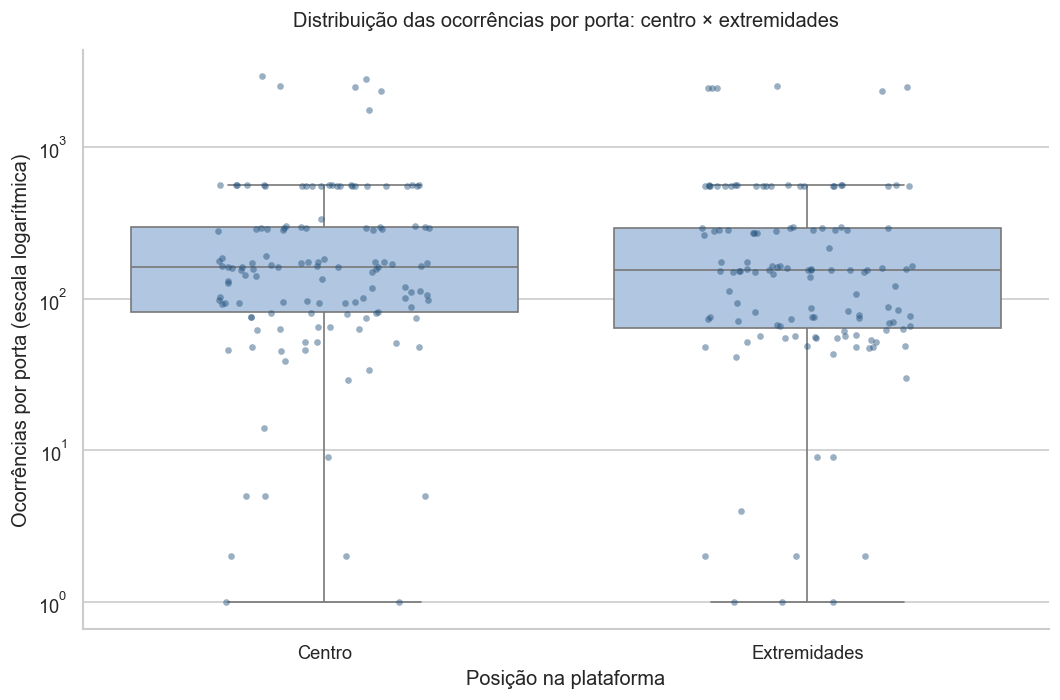

In [58]:
# Distribuição das ocorrências por porta em cada grupo
fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=ocorrencias_por_porta,
    x="Posicao_Plataforma",
    y="Ocorrencias",
    order=["Centro", "Extremidades"],
    showfliers=False,
    color="#A9C5E8",
    ax=ax,
)
sns.stripplot(
    data=ocorrencias_por_porta,
    x="Posicao_Plataforma",
    y="Ocorrencias",
    order=["Centro", "Extremidades"],
    color="#1F4E79",
    alpha=0.45,
    jitter=0.22,
    size=4,
    ax=ax,
)

ax.set_yscale("log")
ax.set_title("Distribuição das ocorrências por porta: centro × extremidades", pad=14)
ax.set_xlabel("Posição na plataforma")
ax.set_ylabel("Ocorrências por porta (escala logarítmica)")
sns.despine()
plt.tight_layout()
plt.show()

## 6. Comparação Estatística entre Centro e Extremidades

Como a distribuição de ocorrências por porta é assimétrica e contém valores extremos, a comparação não será baseada apenas na média geral. Primeiro, será calculada a média de ocorrências por porta no centro e nas extremidades dentro de cada estação e via. Dessa forma, cada uma das 12 combinações estação-via participa da análise como uma unidade de comparação, reduzindo a influência de diferenças operacionais entre estações.

In [59]:
# Média de ocorrências por porta dentro de cada estação e via
comparacao_estacao_via = (
    ocorrencias_por_porta.groupby(
        ["Estação", "Via", "Posicao_Plataforma"],
        observed=True,
    )["Ocorrencias"]
    .mean()
    .unstack("Posicao_Plataforma")
    .reindex(columns=["Centro", "Extremidades"])
    .rename(
        columns={
            "Centro": "Media_Centro",
            "Extremidades": "Media_Extremidades",
        }
    )
    .reset_index()
)

comparacao_estacao_via["Estacao_Via_ID"] = (
    comparacao_estacao_via["Estação"]
    + "_V"
    + comparacao_estacao_via["Via"].astype("string")
)
comparacao_estacao_via["Diferenca_Centro_menos_Extremos"] = (
    comparacao_estacao_via["Media_Centro"]
    - comparacao_estacao_via["Media_Extremidades"]
)
comparacao_estacao_via["Variacao_Percentual"] = (
    comparacao_estacao_via["Diferenca_Centro_menos_Extremos"]
    / comparacao_estacao_via["Media_Extremidades"]
    * 100
)

comparacao_estacao_via = comparacao_estacao_via[[
    "Estacao_Via_ID",
    "Estação",
    "Via",
    "Media_Centro",
    "Media_Extremidades",
    "Diferenca_Centro_menos_Extremos",
    "Variacao_Percentual",
]]

centro_maior = (
    comparacao_estacao_via["Diferenca_Centro_menos_Extremos"] > 0
).sum()
extremos_maior = (
    comparacao_estacao_via["Diferenca_Centro_menos_Extremos"] < 0
).sum()

print(f"Centro com média maior: {centro_maior} de {len(comparacao_estacao_via)} lados/vias")
print(f"Extremidades com média maior: {extremos_maior} de {len(comparacao_estacao_via)} lados/vias")
display(comparacao_estacao_via.round(2))

Centro com média maior: 11 de 12 lados/vias
Extremidades com média maior: 1 de 12 lados/vias


Posicao_Plataforma,Estacao_Via_ID,Estação,Via,Media_Centro,Media_Extremidades,Diferenca_Centro_menos_Extremos,Variacao_Percentual
0,BUT_V1,BUT,1,1376.33,1360.42,15.92,1.17
1,BUT_V2,BUT,2,280.25,276.42,3.83,1.39
2,FAL_V1,FAL,1,91.58,66.64,24.95,37.44
3,FAL_V2,FAL,2,98.58,86.00,12.58,14.63
4,FRA_V1,FRA,1,556.42,556.33,0.08,0.01
5,FRA_V2,FRA,2,556.55,554.64,1.91,0.34
6,FRE_V1,FRE,1,11.60,4.40,7.20,163.64
7,FRE_V2,FRE,2,8.17,25.17,-17.00,-67.55
8,HIG_V1,HIG,1,164.83,154.17,10.67,6.92
9,HIG_V2,HIG,2,170.00,160.09,9.91,6.19


In [60]:
# Teste de permutação pareado exato entre centro e extremidades
diferencas_plataformas = (
    comparacao_estacao_via["Diferenca_Centro_menos_Extremos"]
    .dropna()
    .to_numpy(dtype=float)
)
n_pares = len(diferencas_plataformas)
estatistica_observada = diferencas_plataformas.mean()

# Com 12 pares, todas as 2^12 combinações de sinais podem ser avaliadas
mascaras = np.arange(2 ** n_pares, dtype=np.uint32)[:, None]
bits = (
    (mascaras >> np.arange(n_pares, dtype=np.uint32)) & 1
).astype(int)
sinais = 1 - 2 * bits
medias_permutadas = (
    sinais * diferencas_plataformas
).mean(axis=1)

tolerancia = np.finfo(float).eps * max(1, abs(estatistica_observada))
p_valor_exato = np.mean(
    np.abs(medias_permutadas)
    >= abs(estatistica_observada) - tolerancia
)

resultado_teste_posicao = pd.Series({
    "Pares estação-via": n_pares,
    "Centro com média maior": int((diferencas_plataformas > 0).sum()),
    "Extremidades com média maior": int((diferencas_plataformas < 0).sum()),
    "Diferença média por porta": estatistica_observada,
    "Diferença mediana por porta": np.median(diferencas_plataformas),
    "p-valor exato (bilateral)": p_valor_exato,
}).to_frame("Resultado")

display(resultado_teste_posicao.round(4))
if p_valor_exato < 0.05:
    print("Há evidência estatística de diferença entre os grupos (α = 5%).")
else:
    print("Não há evidência estatística de diferença entre os grupos (α = 5%).")

,Resultado
Pares estação-via,12.0000
Centro com média maior,11.0000
Extremidades com média maior,1.0000
Diferença média por porta,8.8304
Diferença mediana por porta,8.5545
p-valor exato (bilateral),0.0356


Há evidência estatística de diferença entre os grupos (α = 5%).


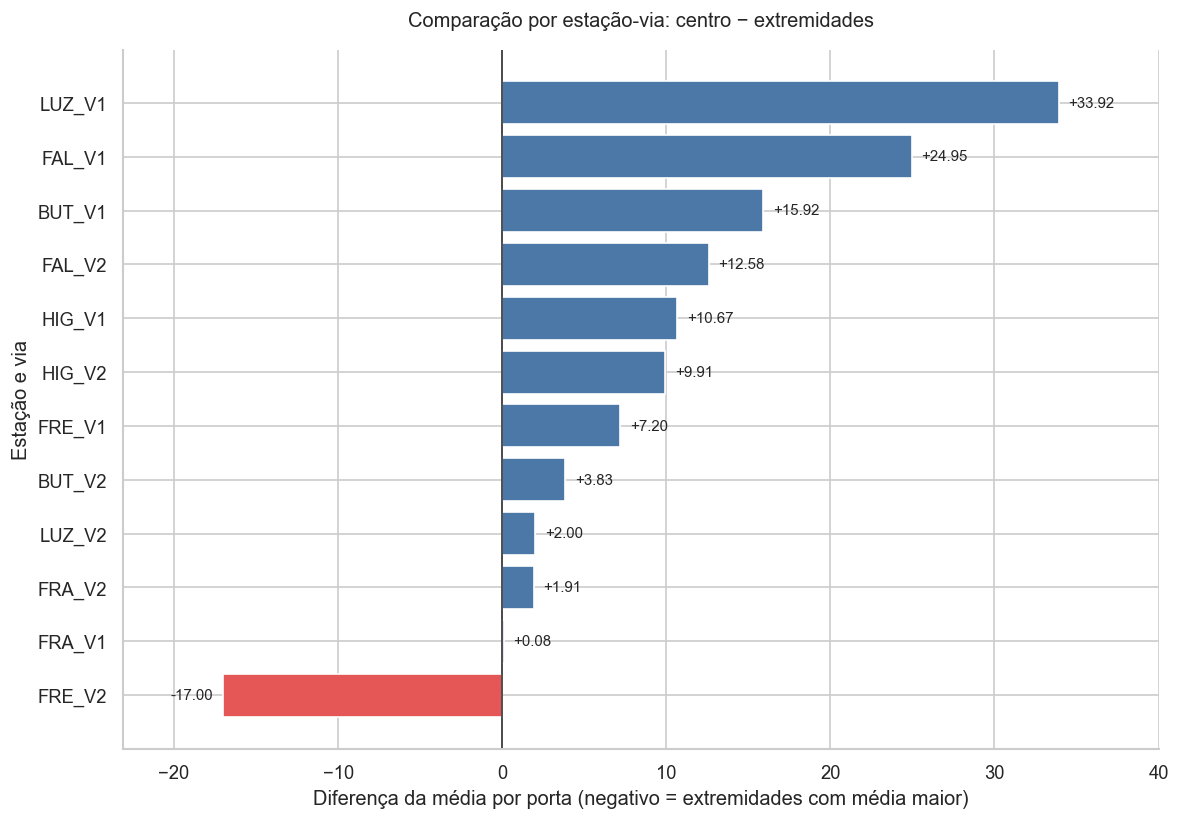

In [61]:
# Diferença entre as médias dentro de cada estação e via
dados_diferenca = comparacao_estacao_via.sort_values(
    "Diferenca_Centro_menos_Extremos"
).copy()
cores = np.where(
    dados_diferenca["Diferenca_Centro_menos_Extremos"] >= 0,
    "#4C78A8",
    "#E45756",
)

fig, ax = plt.subplots(figsize=(10, 7))
barras = ax.barh(
    dados_diferenca["Estacao_Via_ID"],
    dados_diferenca["Diferenca_Centro_menos_Extremos"],
    color=cores,
)
for barra, valor in zip(
    barras,
    dados_diferenca["Diferenca_Centro_menos_Extremos"],
):
    deslocamento = 0.6 if valor >= 0 else -0.6
    ax.text(
        valor + deslocamento,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:+.2f}",
        va="center",
        ha="left" if valor >= 0 else "right",
        fontsize=9,
    )
ax.axvline(0, color="#333333", linewidth=1)
ax.set_title("Comparação por estação-via: centro − extremidades", pad=14)
ax.set_xlabel(
    "Diferença da média por porta "
    "(negativo = extremidades com média maior)"
)
ax.set_ylabel("Estação e via")
ax.margins(x=0.12)
sns.despine()
plt.tight_layout()
plt.show()

## 7. Comparação por Tipo de Alarme

O resultado geral pode ser influenciado pelos tipos mais frequentes. Por isso, a média por porta será comparada separadamente para cada código de alarme. Portas observadas sem determinado tipo receberão contagem zero para esse tipo, evitando que a média considere somente as portas que apresentaram o evento. Para `OBS`, permanecem apenas as ocorrências com duração superior a 60 segundos.

,Total_Ocorrencias,Media_Centro,Media_Extremidades,Diferenca_Percentual
Alarme,,,,
OBS,54424,215.06,208.39,3.20
FO,4617,19.62,16.28,20.52
LSD,4606,17.29,18.57,-6.87
FC,4437,17.82,16.69,6.77
CA,4168,16.00,16.44,-2.68
OA,4128,14.23,17.94,-20.66
CSD,4102,15.81,16.12,-1.93


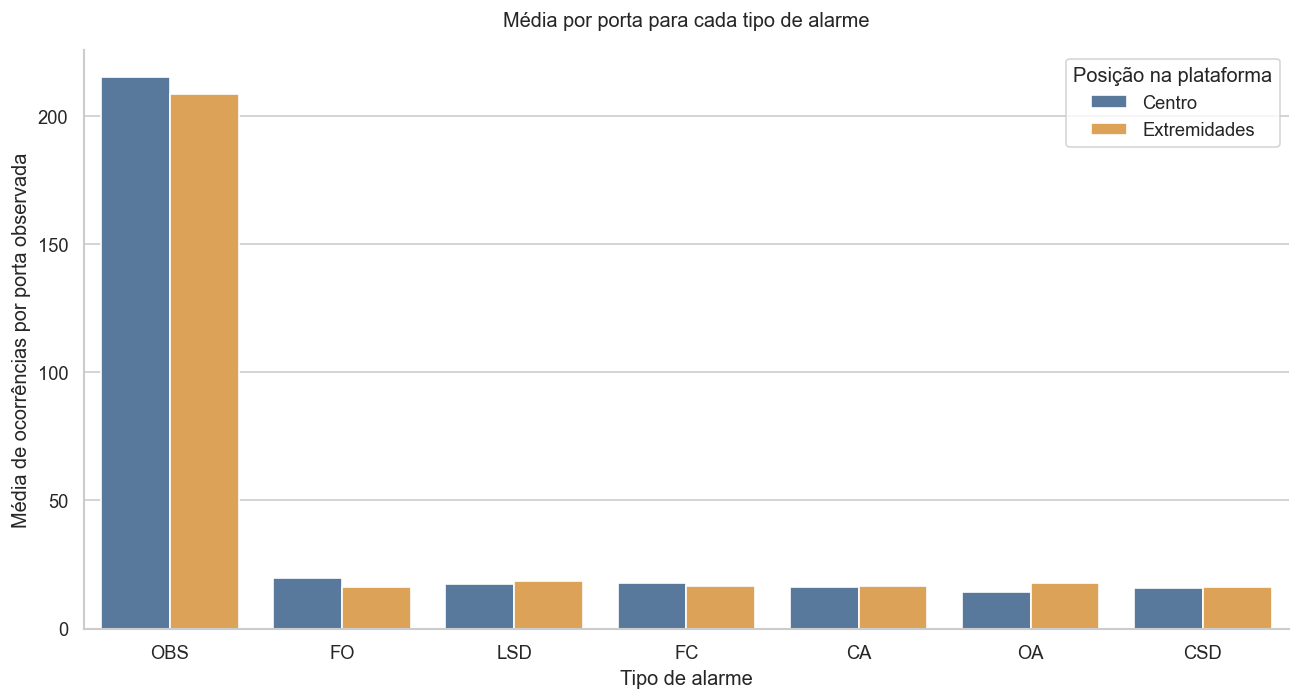

In [62]:
# Contagem de cada tipo de alarme em todas as portas observadas
metadados_portas = (
    ocorrencias_por_porta[["Porta_ID", "Posicao_Plataforma"]]
    .drop_duplicates("Porta_ID")
    .set_index("Porta_ID")
)
tipos_ordenados = df_portas["Alarme"].value_counts().index.tolist()

matriz_contagem_tipo = (
    df_portas.groupby(["Porta_ID", "Alarme"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=metadados_portas.index,
        columns=tipos_ordenados,
        fill_value=0,
    )
)

contagem_porta_tipo = (
    matriz_contagem_tipo
    .join(metadados_portas)
    .reset_index()
    .melt(
        id_vars=["Porta_ID", "Posicao_Plataforma"],
        value_vars=tipos_ordenados,
        var_name="Alarme",
        value_name="Ocorrencias",
    )
)

resumo_tipo_posicao = (
    contagem_porta_tipo.groupby(
        ["Alarme", "Posicao_Plataforma"],
        as_index=False,
        observed=True,
    )
    .agg(
        Total_Ocorrencias=("Ocorrencias", "sum"),
        Media_por_Porta=("Ocorrencias", "mean"),
    )
)

totais_tipo = (
    contagem_porta_tipo.groupby("Alarme", observed=True)["Ocorrencias"]
    .sum()
    .rename("Total_Ocorrencias")
)
medias_tipo = (
    contagem_porta_tipo.groupby(
        ["Alarme", "Posicao_Plataforma"],
        observed=True,
    )["Ocorrencias"]
    .mean()
    .unstack("Posicao_Plataforma")
)
resumo_tipo_alarme = (
    pd.concat([totais_tipo, medias_tipo], axis=1)
    .rename(
        columns={
            "Centro": "Media_Centro",
            "Extremidades": "Media_Extremidades",
        }
    )
)
resumo_tipo_alarme["Diferenca_Percentual"] = (
    resumo_tipo_alarme["Media_Centro"]
    / resumo_tipo_alarme["Media_Extremidades"]
    - 1
) * 100
resumo_tipo_alarme = resumo_tipo_alarme.sort_values(
    "Total_Ocorrencias", ascending=False
)

display(resumo_tipo_alarme.round(2))

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(
    data=resumo_tipo_posicao,
    x="Alarme",
    y="Media_por_Porta",
    hue="Posicao_Plataforma",
    order=tipos_ordenados,
    hue_order=["Centro", "Extremidades"],
    palette=["#4C78A8", "#F2A541"],
    ax=ax,
)
ax.set_title("Média por porta para cada tipo de alarme", pad=14)
ax.set_xlabel("Tipo de alarme")
ax.set_ylabel("Média de ocorrências por porta observada")
ax.legend(title="Posição na plataforma")
sns.despine()
plt.tight_layout()
plt.show()

In [63]:
# Verificação de sensibilidade: OBS versus todos os demais alarmes
contagem_porta_grupo = (
    contagem_porta_tipo.assign(
        Grupo_Alarme=np.where(
            contagem_porta_tipo["Alarme"].eq("OBS"),
            "OBS (> 60 s)",
            "Demais alarmes",
        )
    )
    .groupby(
        ["Porta_ID", "Posicao_Plataforma", "Grupo_Alarme"],
        as_index=False,
        observed=True,
    )["Ocorrencias"]
    .sum()
)

totais_grupo = (
    contagem_porta_grupo.groupby("Grupo_Alarme", observed=True)["Ocorrencias"]
    .sum()
    .rename("Total_Ocorrencias")
)
medias_grupo = (
    contagem_porta_grupo.groupby(
        ["Grupo_Alarme", "Posicao_Plataforma"],
        observed=True,
    )["Ocorrencias"]
    .mean()
    .unstack("Posicao_Plataforma")
)
resumo_obs_demais = (
    pd.concat([totais_grupo, medias_grupo], axis=1)
    .rename(
        columns={
            "Centro": "Media_Centro",
            "Extremidades": "Media_Extremidades",
        }
    )
    .reindex(["OBS (> 60 s)", "Demais alarmes"])
)
resumo_obs_demais["Diferenca_Percentual"] = (
    resumo_obs_demais["Media_Centro"]
    / resumo_obs_demais["Media_Extremidades"]
    - 1
) * 100

display(resumo_obs_demais.round(2))

,Total_Ocorrencias,Media_Centro,Media_Extremidades,Diferenca_Percentual
Grupo_Alarme,,,,
OBS (> 60 s),54424,215.06,208.39,3.20
Demais alarmes,26058,100.77,102.03,-1.24


## 8. Distribuição por Número da Porta

Além da divisão entre centro e extremidades, será verificado o comportamento individual das posições `01` a `24`. A média será calculada somente entre as portas físicas observadas na base; posições ausentes não serão tratadas como zero, pois o arquivo de alarmes possui registros omitidos na exportação.

,Portas_Observadas,Total_Ocorrencias,Media_por_Porta,Mediana_por_Porta
Porta,,,,
1,11,4391,399.18,150.0
2,10,4382,438.20,160.0
3,11,4280,389.09,155.0
4,12,4473,372.75,116.0
5,12,4488,374.00,122.5
6,11,4518,410.73,150.0
7,12,5091,424.25,151.0
8,11,4573,415.73,169.0
9,11,4682,425.64,163.0


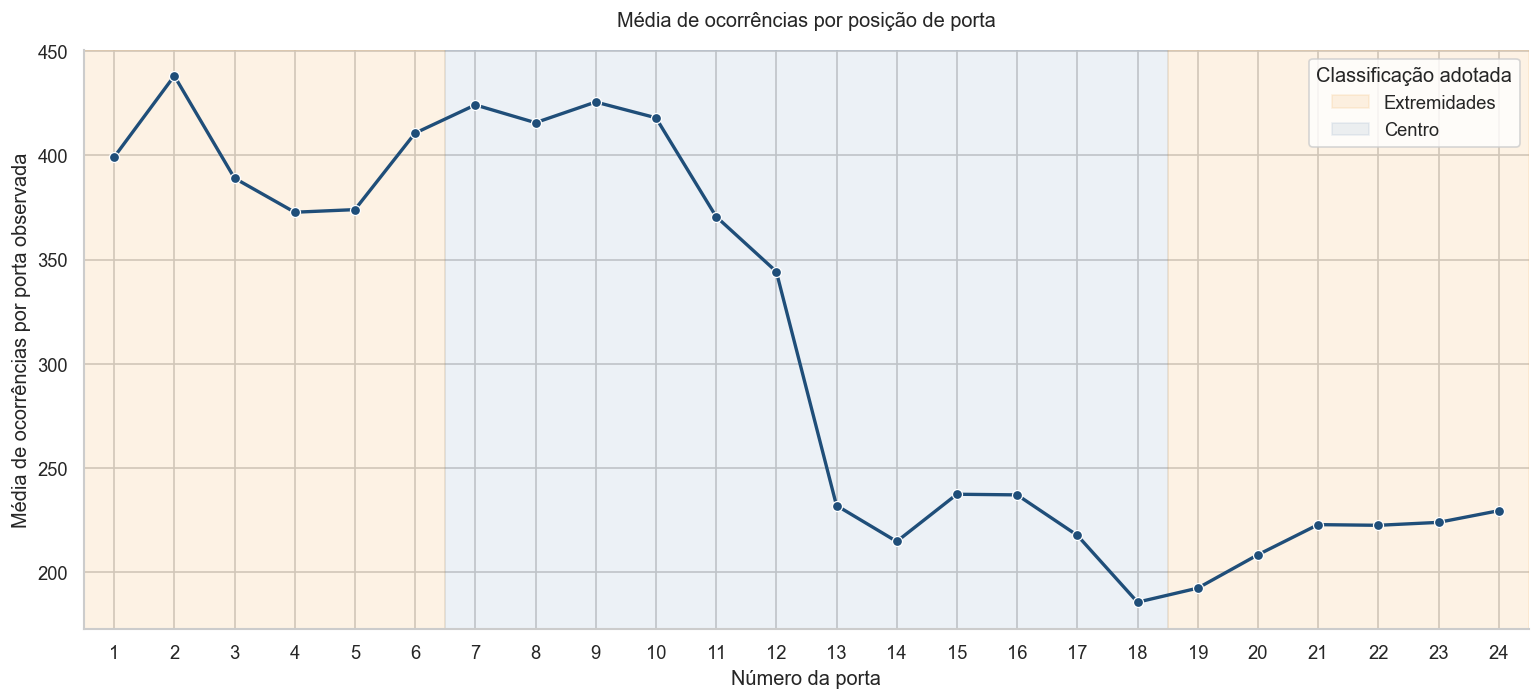

In [64]:
# Perfil das ocorrências ao longo das 24 posições de porta
resumo_numero_porta = (
    ocorrencias_por_porta.groupby("Porta", observed=True)
    .agg(
        Portas_Observadas=("Porta_ID", "nunique"),
        Total_Ocorrencias=("Ocorrencias", "sum"),
        Media_por_Porta=("Ocorrencias", "mean"),
        Mediana_por_Porta=("Ocorrencias", "median"),
    )
    .reindex(pd.Index(range(1, 25), name="Porta"))
)

display(resumo_numero_porta.round(2))

fig, ax = plt.subplots(figsize=(13, 6))
ax.axvspan(0.5, 6.5, color="#F2A541", alpha=0.14, label="Extremidades")
ax.axvspan(6.5, 18.5, color="#4C78A8", alpha=0.10, label="Centro")
ax.axvspan(18.5, 24.5, color="#F2A541", alpha=0.14)
sns.lineplot(
    data=resumo_numero_porta.reset_index(),
    x="Porta",
    y="Media_por_Porta",
    marker="o",
    color="#1F4E79",
    linewidth=2,
    ax=ax,
)
ax.set_xticks(range(1, 25))
ax.set_xlim(0.5, 24.5)
ax.set_title("Média de ocorrências por posição de porta", pad=14)
ax.set_xlabel("Número da porta")
ax.set_ylabel("Média de ocorrências por porta observada")
ax.legend(title="Classificação adotada")
sns.despine()
plt.tight_layout()
plt.show()

## 9. Conclusão da Hipótese

Após os filtros, foram analisadas **80.482 ocorrências PDM válidas**, distribuídas entre **257 portas observadas**. O centro apresentou 41.058 ocorrências em 130 portas, enquanto as extremidades apresentaram 39.424 ocorrências em 127 portas. As médias foram, respectivamente, **315,83** e **310,43 ocorrências por porta**, uma diferença de apenas **1,74%** a favor do centro.

Na comparação pareada, o centro apresentou média maior em **11 das 12 combinações estação-via**. O teste de permutação pareado exato resulta em um valor de *p* próximo de **0,036**, indicando uma diferença estatisticamente detectável ao nível de 5%. Entretanto, a magnitude prática da diferença geral é pequena.

O resultado também não é uniforme entre os defeitos. `OBS` representa **67,62%** das ocorrências válidas e apresenta média 3,20% maior no centro. Quando `OBS` é retirado, os demais alarmes, em conjunto, apresentam média aproximadamente **1,24% menor** no centro. Individualmente, `FO` e `FC` são mais frequentes no centro, enquanto `OA`, `LSD`, `CA` e `CSD` apresentam médias maiores nas extremidades.

A análise das posições `01–24` também não revela um pico central simétrico: as posições de numeração inicial concentram médias maiores do que as posições finais. Portanto, a hipótese recebe **suporte parcial e fraco**. Existe um padrão consistente de pequena elevação no centro entre os lados/vias, mas não há evidência suficiente para afirmar que portas centrais, supostamente mais utilizadas, apresentam mais defeitos de maneira geral.

Essa conclusão deve ser interpretada com cautela: a posição central é apenas uma aproximação de uso; não há dados de fluxo de passageiros nem localização dos acessos; o arquivo cobre somente seis estações; e a própria exportação informa que parte dos dados pode ter sido omitida. Assim, os resultados indicam associação entre posição e alarmes, mas não demonstram causalidade entre maior utilização e defeito.